In [11]:
 
# Now we will build an dataloader which is going to work as middle layer between model and dataset
# As model cant learn raw jpgm files or jsob files 
class Camera_Dataset(Dataset):

    # First method init method 
    def __init__(self, images_folder, path_annotations, transform=None):
        self.images_folder = images_folder
        self.path_annotations = path_annotations
        self.transform = transform
        with open(path_annotations, "r", encoding="utf-8") as f:
            self.annotations = json.load(f)
        final_ids = sorted(set(a["category_id"] for a in self.annotations))
        # The dataset COCO annotation format have incosistent catogory ids
        # Hence it is needed to labled them sequence wise starting from 0 for pytorch
        # Creating lable map dictonary
        self.label_map = {cat_id: slot for slot, cat_id in enumerate(final_ids)}
        
    # Counting annotation:--
    def __len__(self):   # Len dunder is used insted of normal class because we specifically need the length of data
        return len(self.annotations)
        
    # Get item method 
    # Now we need images one after other to paas it into model hence we will write our getitem method:--
    # This will get us the images for model training from our processed data
    def __getitem__(self, index):
        # First we will fetch annotation of image positioned at index
        annotation_data = self.annotations[index]
        # Now we will build an full path to the image :--
        # This will combine folder path with specific image 
        test_image_path = os.path.join(self.images_folder, annotation_data["image_id"]+".jpg")
        #   Opening of image:--
        Img = Image.open(test_image_path)
        Img = Img.convert("RGB")
        # Fetching label for image :--
        lb=self.label_map[annotation_data["category_id"]]
        # Transform :--
        if self.transform :
            Img = self.transform(Img)
        return Img,lb
   
    
# Cerating data_set object as d , data which is already loaded in pre-processed folder:--
d=Camera_Dataset(
        r"D:\Camera_trap\data\processed_data",
        r"D:\Camera_trap\data\processed_data\prepared_annotations.json",  
        transform = transform_image
)
# Lets count how many annotation are present 
# TEsting of labled annotation
print(type(d.annotations))  # List is the type where annotaion are stored
print(len(d))
print(d.label_map)

<class 'list'>
44232
{1: 0, 3: 1, 5: 2, 6: 3, 7: 4, 8: 5, 9: 6, 10: 7, 11: 8, 16: 9, 34: 10, 51: 11, 99: 12}


In [12]:
# We need to test that all the 4 things 

image, label = d[0]
print(image.shape,image.dtype, "label:", label)






#Hence we got the 44232 annotation which confirms that list all 44,232 annotation working which we calculated in our pre-processing:--
# Lets explore particullarly one annotation so we can use it in our model implementation:--
print(d.annotations[0])

torch.Size([3, 224, 224]) torch.float32 label: 0
{'image_id': '5998cfa4-23d2-11e8-a6a3-ec086b02610b', 'category_id': 1, 'bbox': [156.0, 304.86961178045516, 110.4, 85.53895582329315]}


In [13]:
# Now we need images one after other to paas it into model hence we will write our getitem method:--
# This will get us the images for model training
def __getitem__ (self, index):
    # First we will fetch annotation of image positioned at index
    annotation_data = self.annotations[index]
    # Now we will build an full path to the image :--
    # This will combine folder path with specific image 
    test_image_path = os.path.join(self.images_folder, annotation_data["image_id"]+".jpg")
    # Opening of image:--
    Img = Image.open(test_image_path)
    Img = Img.convert("RGB")

    # Fetching label for image :--
    lb=self.label_map[annotation_data["category_id"]]

    # Transform :--
    if self.transform :
        Img = self.transform(Img)
    return Img,lb
    

In [14]:
# The images we got those are PIL(Python Image Library) images
# We need to convert this PIl image into an Tensor image 
# Tensor image is an image which represented as multi-dimensional array which is an image understable by Deel learning model 
# Insted of JPEG or PNG files we will use tensor images 

In [15]:
# Conversion of images into tensor :--
# We need to normal\ize image first :--
# Normalization of an image = Pixel-Mean/ Standard Deviation 
from torchvision import transforms
standard_deviation = [0.229,0.224,0.225]
Mean = [0.485,0.456,0.406]
# Transform function :--
transform_image = transforms.Compose([
    # Conversion of image to 224*224 
    # Resizing every image which is expected by ResNet-50
    transforms.Resize((224,224)),
    # Conversion of PIl image into pytorch tensor image
    # Change pixel value from 0-255 to 0.0-1.0
    transforms.ToTensor(),
    # AGain normalize into using  ImageNetstats:--
    transforms.Normalize(Mean, standard_deviation)
])

In [16]:
# Now we got the pre-processed, resized , labled tensor images data 
# Hence we need to divide this data into two catogories 
# 1. Train , 2. Test
# 1. Train :-- This will use to teach the model 
# 2. Test :-- This will use to test and evaluate the model 
# We will follow the standard test/train split which is 80/20
# 80 % of our data we will use to train our model 
# 20 % of our data we will use to test model

from torch.utils.data import random_split 

dataset_full_size = len(d)

# Lets define train size first :--
dataset_train = int(dataset_full_size * 0.8)
# Test size :--
dataset_test = dataset_full_size - dataset_train

# Splliting images randomly using pytorch:;--
dataset_train,dataset_test = random_split(d,[dataset_train,dataset_test])

print(f"Total = {dataset_full_size}")
# Train size:--
print(f"Train size={len(dataset_train)}")
# Test size:--
print(f"Test size ={len(dataset_test)}")


import torch
torch.manual_seed(42)

dataset_train_size = int(dataset_full_size * 0.8)
dataset_test_size = dataset_full_size - dataset_train_size
dataset_train, dataset_test = random_split(d, [dataset_train_size, dataset_test_size])

print(f"Train size = {len(dataset_train)}")
print(f"Test size = {len(dataset_test)}")


Total = 44232
Train size=35385
Test size =8847
Train size = 35385
Test size = 8847


In [17]:
# Hence we got that the data is now divided into two types
# Now we need to build data-loader 
# Data-loader :-- This method used to wrap dataset and handles the batching of random images 
# As we do not need to pass single image , one image at a time pass by Dataset to model hence we use dataloader
from torch.utils.data import DataLoader  # DataLoader class
# We will take a batch of 32 images together 
batch_size = 32

# First we will build loader for our train data
## Data loader method loads 32 images in batches from dataset_test
dataset_train_loader = DataLoader(
    dataset_train,
    batch_size=32,
    shuffle = True  # This will not let model to become biased learning   
)

# Build Loader for test data :--
# Data loader method loads 32 images in batches from dataset_test
dataset_test_loader = DataLoader(
    dataset_test,
    batch_size =32,
    shuffle = False 
)

# Lets check by fetching one batch 
images,labels = next(iter(dataset_train_loader))
print("Example images batch = ", images.shape)
print("Example lables batch =" ,labels.shape)



    


Example images batch =  torch.Size([32, 3, 224, 224])
Example lables batch = torch.Size([32])


In [18]:
# Now we will build ResNet-50 (Neural Network):--
import torch 
import torch.nn as nn
import torchvision.models as models

# The system where model will implement:--
system = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("GPU Device" , system)

# We need to load pre-trained resnet-50 model first :--
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Replacewew the final classification layer :--
num_features = model.fc.in_features
num_classes = len(d.label_map)


model.fc = nn.Linear(num_features, num_classes)

# Step 3: Move the model to the selected device
model = model.to(system)

print("Final layer now outputs:", model.fc.out_features, "classes")



GPU Device cuda
Final layer now outputs: 13 classes


In [19]:
# As we can see ResNet 50 is no build on GPU and final layer outout is 13 classes
# Step -4 :--
# we need to build an loss function which generates measurment of false predection of model
# We will build an optimizer which tells us that how model updates its weights to perform less mistakes

import torch
import torch.nn as nn

# Loss function — standard for multi-class classification
criterion = nn.CrossEntropyLoss()

# Optimiser — Adam
# Learning rate controls how large each weight update is
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function and optimiser are ready to use ")


Loss function and optimiser are ready to use 


In [20]:
# Now we are all ready with model for our training loop
# This is step-5 under which we will train our model 
# Theree are 5 steps which we need to follow:--
# 1. Forward pass :-- The batch of images is pass through ResNet-50
# we also got logits which are raw prediction scores , model is making an initial guess 
# 2. Compute Loss:-- This compares the prediction of model with orignak labels\
# The loss function measures that how many false predction are there
# 3. Backward Pass :-- This will return the weight contribute to the error by every weight
# 4. Update weights :-- The optimizer uses those things to update weights 
# Example:-- Make a mistake-> learn from it -> Adjust your understanding -> And gives better results next time
# 5. Zero gradiants:-- This will reset all values to default hence the next batch starts from fresh values 
# First define the number of times model will need to execute:--
num_stage = 5
for epoch in range (num_stage):
    model.train()   # This will take model in training mode 
    running_loss = 0.0
    for images , labels in dataset_train_loader:
        images , labels = images.to(system) , labels.to(system)
        # 5 Steps to perform :--
        # FIrst we need to perform fifth step clear previous output:--
        optimizer.zero_grad()
        # Second step = Forward pass:--
        outputs = model(images)
         # Thirs step= Compute the loss
        loss = criterion(outputs, labels)
        # Fourth step = Backpropagation:-
        loss.backward()
        # Sixth step = Update the model weights
        optimizer.step()
        # Keep track of the total training loss
        running_loss += loss.item()
         # Print the average loss for this epoch
    average_loss = running_loss / len(dataset_train_loader)
    print(f"Epoch [{epoch+1}/{num_stage}]  Loss: {average_loss:.4f}")

Epoch [1/5]  Loss: 0.5722
Epoch [2/5]  Loss: 0.1648
Epoch [3/5]  Loss: 0.0841
Epoch [4/5]  Loss: 0.0624
Epoch [5/5]  Loss: 0.0532


In [21]:
# Saving the model and then evuulaliting it :--]
# Saving model first :--
torch.save(model.state_dict(), r"D:\Camera_trap\resnet50_trained.pth")
print("model saved")

# state_dict saves the model output at the given path 



# We are done with the model training , now we need to evulate this and wants to see theoutcome 
# Evuluation of Resnet 50 image classifier :--
# We will do  this on the basis of correctness of model 
# For that we need to put model in evulation mode not in learning mode :--
model.eval()  # Evulation mode 

true = 0   # counter for correct predictions
total = 0  # counter for total images seen

with torch.no_grad():
    # We only need to fetch the images and labels present in the test folder because this is evulation 
    
    for images, labels in dataset_test_loader: 
        images, labels = images.to(system), labels.to(system) # Moing of same batch data to our system
        # Passing images as input through neural network and lets get the outome :-
        predictions = model(images)
        # Lets get the highest scofre as prediction :--
        _, predicted_class= torch.max(predictions,1)
        # Counting numbers of true in this :--
        true += (predicted_class == labels).sum().item()
        total += labels.size(0)  # add batch size to total

# Lets calculate actuall accuracy 
perfect_result = true*100/total
print(f"We got the result as {perfect_result :.2f}")

model saved
We got the result as 95.35


In [22]:
# The model is perforning well across the test dataset which contains 8847 images for testing , but the catch is there might be an class imbalance 
# We get to know this thing once we will get confusion matxix and class accuracy per each class will tell you 

In [23]:
# Confusion matrix 
import sklearn
import seaborn
# sklearn :-- gives us matroix and per class report [gives us correct and incorrect precdiction for each class]
# seaborn :-- used for plotting graph
# We have sucessfully installed seaborn 


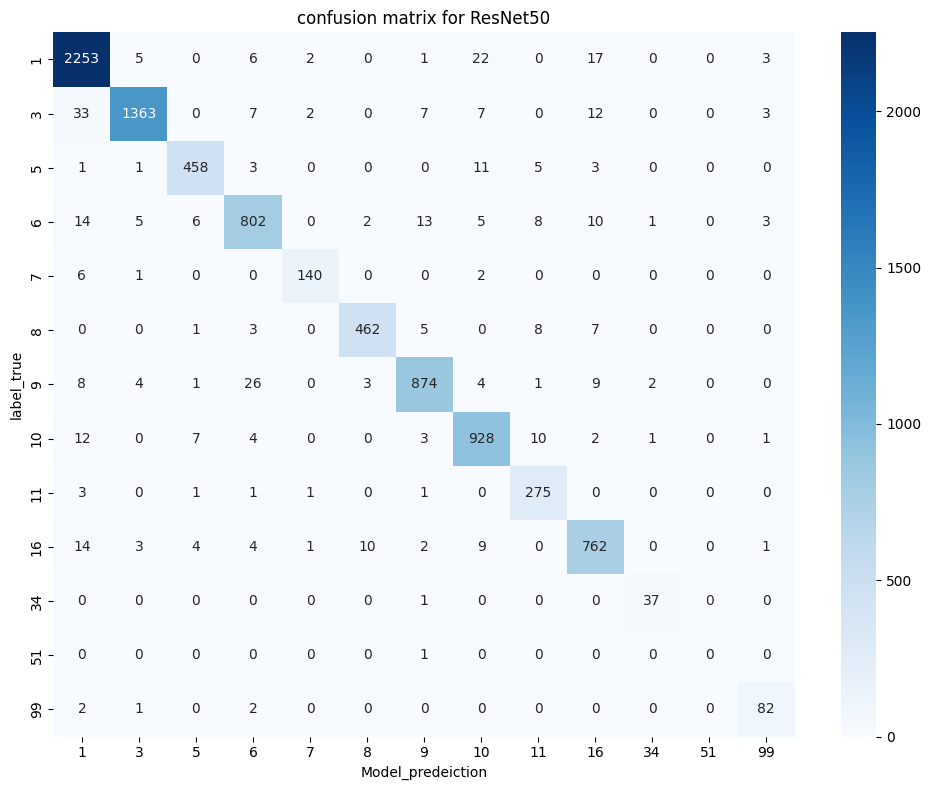

              precision    recall  f1-score   support

           1       0.96      0.98      0.97      2309
           3       0.99      0.95      0.97      1434
           5       0.96      0.95      0.95       482
           6       0.93      0.92      0.93       869
           7       0.96      0.94      0.95       149
           8       0.97      0.95      0.96       486
           9       0.96      0.94      0.95       932
          10       0.94      0.96      0.95       968
          11       0.90      0.98      0.93       282
          16       0.93      0.94      0.93       810
          34       0.90      0.97      0.94        38
          51       0.00      0.00      0.00         1
          99       0.88      0.94      0.91        87

    accuracy                           0.95      8847
   macro avg       0.87      0.88      0.87      8847
weighted avg       0.95      0.95      0.95      8847



D:\anaconda3\envs\cameratrap\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda3\envs\cameratrap\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda3\envs\cameratrap\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [24]:
# Confusion matrix and classification report 
# Import essential liberaries 
from sklearn.metrics import confusion_matrix  # metrics is used to get the performance matrix
from sklearn.metrics import classification_report  # classificaiton report gives detail of performance for each class
import matplotlib.pyplot as plt  # used for graphs an figures 
import seaborn as s  # output of confusion matrix takes seabornh and displays it in labels,title and figure 

# Lets get model into evulation mode 
model.eval()

# Lets get total prediction ad total true labels 
total_model_prediction = []
total_model_labels = []

with torch.no_grad():
    for images, labels in dataset_test_loader:
        images, labels = images.to(system), labels.to(system)  # Move both tensors to GPU

        # Everyhting is done now lets perform forward pass:--
        scores = model(images)

        _, predicted = torch.max(scores, 1)  # Checks for the highest accuracy from all classes

        total_model_prediction.extend(predicted.cpu().numpy())
        total_model_labels.extend(labels.cpu().numpy())

# lets build 13*13 matrix to store
matrix_confusion = confusion_matrix(total_model_labels, total_model_prediction)

# sort classes in corret order 
all_classes_sorted = [str(name) for name, idx in sorted(d.label_map.items(), key=lambda x: x[1])]
# plotting 
plt.figure(figsize=(10, 8))

s.heatmap(
    matrix_confusion,
    annot=True,                      # gives numbers inside boxes
    fmt="d",                         # shows integers
    cmap="Blues",                    # shows data on blue scale
    xticklabels=all_classes_sorted,  # shows classs name on x-axis
    yticklabels=all_classes_sorted   # shows classs name on y-axis
)

# Label the graph 
plt.xlabel("Model_predeiction")
plt.ylabel("label_true")
plt.title("confusion matrix for ResNet50")
plt.tight_layout()

# display graph
plt.show()

print(classification_report(
    total_model_labels,
    total_model_prediction,
    target_names=all_classes_sorted
))

In [25]:
# 9 important things for evulation of ResNet50 model
# 1. model.eval()                 → Switch model to evaluation mode
# 2. torch.no_grad()              → Disable gradient calculations
# 3. Loop through val_loader      → Process validation batches
# 4. outputs = model(images)      → Get model predictions
# 5. torch.max()                  → Choose the predicted class
# 6. Store predictions & labels   → Build complete lists
# 7. confusion_matrix()           → Compare predictions with true labels
# 8. sns.heatmap()                → Visualize the confusion matrix
# 9. classification_report()      → Print precision, recall, F1-score, and support

In [26]:
# Saving the confusion matrix 
plt.tight_layout() # Trim it so that we can get the perfect matrix for our showcase
plt.savefig(r"D:\Camera_trap\confusion_matrix_resnet50.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [27]:
# Saving the classification report :--
stats_report_cl = classification_report(
    total_model_labels,
    total_model_prediction,
    labels = sorted(set(total_model_labels)),
    target_names=all_classes_sorted
    
)
# Creating file and writing the text 
with open(r"D:\Camera_trap\classification_report_resnet50.txt", "w") as f:
    f.write(stats_report_cl)

print(stats_report_cl)
print("Report saved succesfully")



              precision    recall  f1-score   support

           1       0.96      0.98      0.97      2309
           3       0.99      0.95      0.97      1434
           5       0.96      0.95      0.95       482
           6       0.93      0.92      0.93       869
           7       0.96      0.94      0.95       149
           8       0.97      0.95      0.96       486
           9       0.96      0.94      0.95       932
          10       0.94      0.96      0.95       968
          11       0.90      0.98      0.93       282
          16       0.93      0.94      0.93       810
          34       0.90      0.97      0.94        38
          51       0.00      0.00      0.00         1
          99       0.88      0.94      0.91        87

    accuracy                           0.95      8847
   macro avg       0.87      0.88      0.87      8847
weighted avg       0.95      0.95      0.95      8847

Report saved succesfully


D:\anaconda3\envs\cameratrap\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda3\envs\cameratrap\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda3\envs\cameratrap\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
